In [6]:
from pathlib import Path
import shutil
import random
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import SimpleITK as sitk
from scipy.ndimage import gaussian_filter

In [ ]:
from glob import glob
import os

raw_data_dir =Path("workflow/dflows_magnitude_ahc/imagesTs_enhanced")

image_files = sorted(list(raw_data_dir.glob("*.nii.gz")))

print(f"Images source: {raw_data_dir}")

Images source: /workspace/4dflows_magnitude_ahc/imagesTs_enhanced


In [18]:
print(f"Found images: {len(image_files)}")


Found images: 563


In [10]:
processed_dir = Path("/workspace/4dflows_magnitude_ahc/imagesTs_enhanced")

sample_file = list(processed_dir.glob("*.nii.gz"))
sample_file

[PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f00_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f01_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f02_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f03_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f04_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f05_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f06_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f07_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f08_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f09_0000.nii.gz'),
 PosixPath('/workspace/4dflows_magnitude_ahc/imagesTs_enhanced/VS001_f10_0000.nii.gz'),
 PosixPath('/workspace/4dflows_m

In [10]:
SOURCE_DIR = Path("/workspace/4Dflows")
OUTPUT_DIR_IMAGES = Path("/workspace/4dflows_magnitude_ahc/imageTs")
OUTPUT_DIR_LABELS = Path("/workspace/4dflows_magnitude_ahc/labelsTs")
OUTPUT_DIR_IMAGES.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR_LABELS.mkdir(parents=True, exist_ok=True)



# create imagsTs from ahc_4dflow data
get all magnitude images for all patients and move them to folder each frame name will be VSxx_fyy_0000
where xx is patient no
yy frame no

In [11]:

# Sort patient folders numerically
patients = sorted(
    [p for p in SOURCE_DIR.iterdir() if p.is_dir()],
    key=lambda x: int(x.name)
)

for patient_idx, patient_dir in enumerate(patients, start=1):

    # Find the folder ending exactly with _OBL
    obl_folders = [
        f for f in patient_dir.iterdir()
        if f.is_dir() and f.name.endswith("_OBL")
    ]

    if len(obl_folders) != 1:
        print(f"Skipping {patient_dir.name}: found {len(obl_folders)} OBL folders")
        continue

    obl_folder = obl_folders[0]

    volumes = sorted(obl_folder.glob("volume_*.nii.gz"))

    for vol_idx, vol_file in enumerate(volumes):

        new_name = (
            f"VS{patient_idx:03d}_f{vol_idx:02d}_0000.nii.gz"
        )

        dst_file = OUTPUT_DIR_IMAGES / new_name

        shutil.copy2(vol_file, dst_file)

    print(
        f"Patient {patient_dir.name} -> "
        f"VS{patient_idx:03d} ({len(volumes)} volumes)"
    )

print("Done.")

Patient 29149 -> VS001 (22 volumes)
Patient 29241 -> VS002 (19 volumes)
Patient 29255 -> VS003 (17 volumes)
Patient 29336 -> VS004 (20 volumes)
Patient 29465 -> VS005 (13 volumes)
Patient 29528 -> VS006 (16 volumes)
Patient 30266 -> VS007 (18 volumes)
Patient 31122 -> VS008 (22 volumes)
Patient 31123 -> VS009 (23 volumes)
Patient 31248 -> VS010 (16 volumes)
Patient 31252 -> VS011 (19 volumes)
Patient 31506 -> VS012 (27 volumes)
Patient 31509 -> VS013 (16 volumes)
Patient 31510 -> VS014 (13 volumes)
Patient 31525 -> VS015 (17 volumes)
Patient 33139 -> VS016 (22 volumes)
Patient 33569 -> VS017 (20 volumes)
Patient 33570 -> VS018 (20 volumes)
Patient 33724 -> VS019 (20 volumes)
Patient 33728 -> VS020 (16 volumes)
Patient 34023 -> VS021 (15 volumes)
Patient 34486 -> VS022 (15 volumes)
Patient 34634 -> VS023 (15 volumes)
Patient 36672 -> VS024 (15 volumes)
Patient 37345 -> VS025 (21 volumes)
Patient 37472 -> VS026 (20 volumes)
Patient 37492 -> VS027 (15 volumes)
Patient 37498 -> VS028 (15 v

# create imagesTs_enhanced process each volume and save it

1-Load NIfTI.

2-Clip extreme intensities (1st-99th percentile).

3-Apply anisotropic diffusion denoising (edge-preserving).

4-Z-score normalization.

5-Mild unsharp masking (very gentle).

6-Save with the same filename.

In [15]:


# =========================
# Paths
# =========================
input_dir = OUTPUT_DIR_IMAGES
output_dir = Path("/workspace/4dflows_magnitude_ahc/imagesTs_enhanced")
output_dir.mkdir(exist_ok=True)
# =========================
# Processing Loop
# =========================

nii_files = sorted(input_dir.glob("*.nii.gz"))

print(f"Found {len(nii_files)} files")

for nii_file in nii_files:

    print(f"Processing {nii_file.name}")

    # -------------------------
    # Load image
    # -------------------------

    img = nib.load(str(nii_file))
    data = img.get_fdata().astype(np.float32)

    # -------------------------
    # Percentile clipping
    # -------------------------

    p1 = np.percentile(data, 1)
    p99 = np.percentile(data, 99)

    data = np.clip(data, p1, p99)

    # -------------------------
    # Convert to SimpleITK
    # -------------------------

    sitk_img = sitk.GetImageFromArray(data)

    # -------------------------
    # Edge-preserving denoising
    # -------------------------

    denoised_img = sitk.CurvatureAnisotropicDiffusion(
        sitk_img,
        timeStep=0.0625,
        conductanceParameter=3.0,
        numberOfIterations=5
    )

    denoised = sitk.GetArrayFromImage(
        denoised_img
    ).astype(np.float32)

    # -------------------------
    # Z-score normalization
    # -------------------------

    mean = denoised.mean()
    std = denoised.std()

    denoised = (denoised - mean) / (std + 1e-8)

    # -------------------------
    # Mild sharpening
    # -------------------------

    blur = gaussian_filter(
        denoised,
        sigma=1
    )

    sharpened = denoised + 0.2 * (
        denoised - blur
    )

    # -------------------------
    # Save
    # -------------------------

    out_img = nib.Nifti1Image(
        sharpened.astype(np.float32),
        affine=img.affine,
        header=img.header
    )

    out_path = output_dir / nii_file.name

    nib.save(out_img, str(out_path))

print("Done.")

Found 563 files
Processing VS001_f00_0000.nii.gz
Processing VS001_f01_0000.nii.gz
Processing VS001_f02_0000.nii.gz
Processing VS001_f03_0000.nii.gz
Processing VS001_f04_0000.nii.gz
Processing VS001_f05_0000.nii.gz
Processing VS001_f06_0000.nii.gz
Processing VS001_f07_0000.nii.gz
Processing VS001_f08_0000.nii.gz
Processing VS001_f09_0000.nii.gz
Processing VS001_f10_0000.nii.gz
Processing VS001_f11_0000.nii.gz
Processing VS001_f12_0000.nii.gz
Processing VS001_f13_0000.nii.gz
Processing VS001_f14_0000.nii.gz
Processing VS001_f15_0000.nii.gz
Processing VS001_f16_0000.nii.gz
Processing VS001_f17_0000.nii.gz
Processing VS001_f18_0000.nii.gz
Processing VS001_f19_0000.nii.gz
Processing VS001_f20_0000.nii.gz
Processing VS001_f21_0000.nii.gz
Processing VS002_f00_0000.nii.gz
Processing VS002_f01_0000.nii.gz
Processing VS002_f02_0000.nii.gz
Processing VS002_f03_0000.nii.gz
Processing VS002_f04_0000.nii.gz
Processing VS002_f05_0000.nii.gz
Processing VS002_f06_0000.nii.gz
Processing VS002_f07_0000.n

### visual comparison origignal vs processed

Sample: VS019_f00_0000.nii.gz


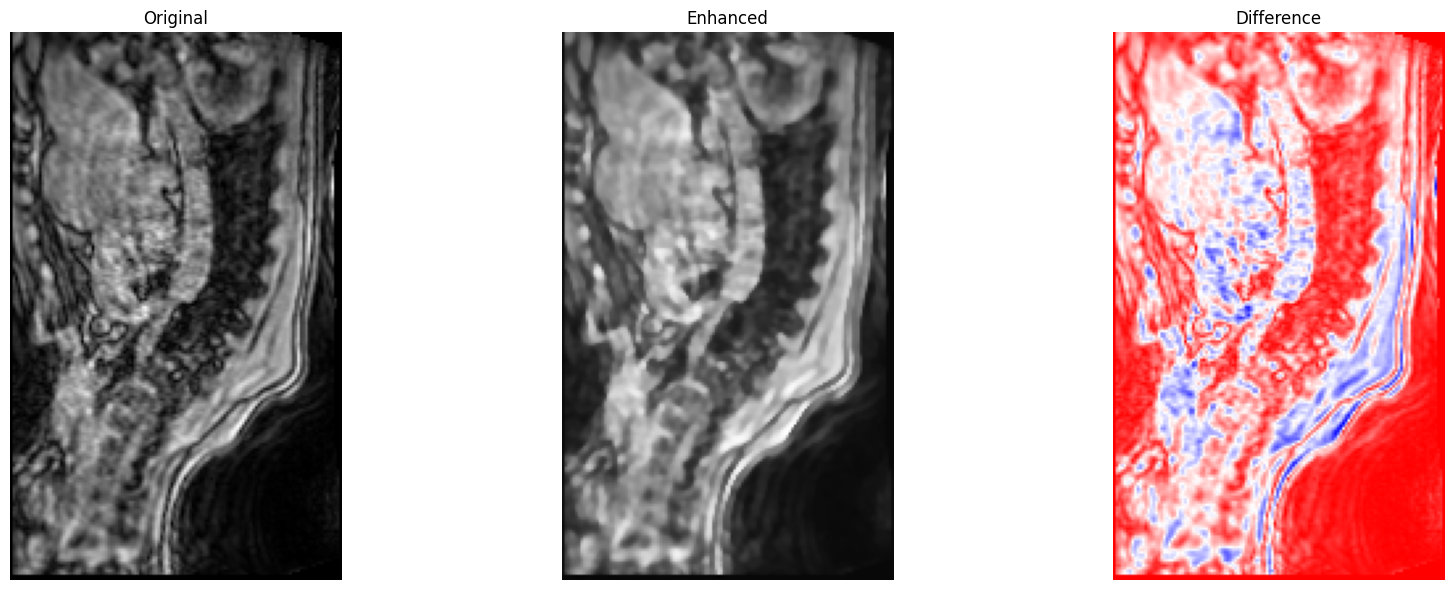

In [25]:
original_dir = Path("/workspace/4dflows_magnitude_ahc/imageTs")
processed_dir = Path("/workspace/4dflows_magnitude_ahc/imagesTs_enhanced")

sample_file = random.choice(list(original_dir.glob("*.nii.gz")))

print("Sample:", sample_file.name)

orig = nib.load(str(sample_file)).get_fdata()
proc = nib.load(str(processed_dir / sample_file.name)).get_fdata()

z = orig.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(orig[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(proc[:, :, z].T, cmap="gray", origin="lower")
axes[1].set_title("Enhanced")
axes[1].axis("off")

axes[2].imshow((proc - orig)[:, :, z].T,
               cmap="bwr",
               origin="lower")
axes[2].set_title("Difference")
axes[2].axis("off")

plt.tight_layout()
plt.show()

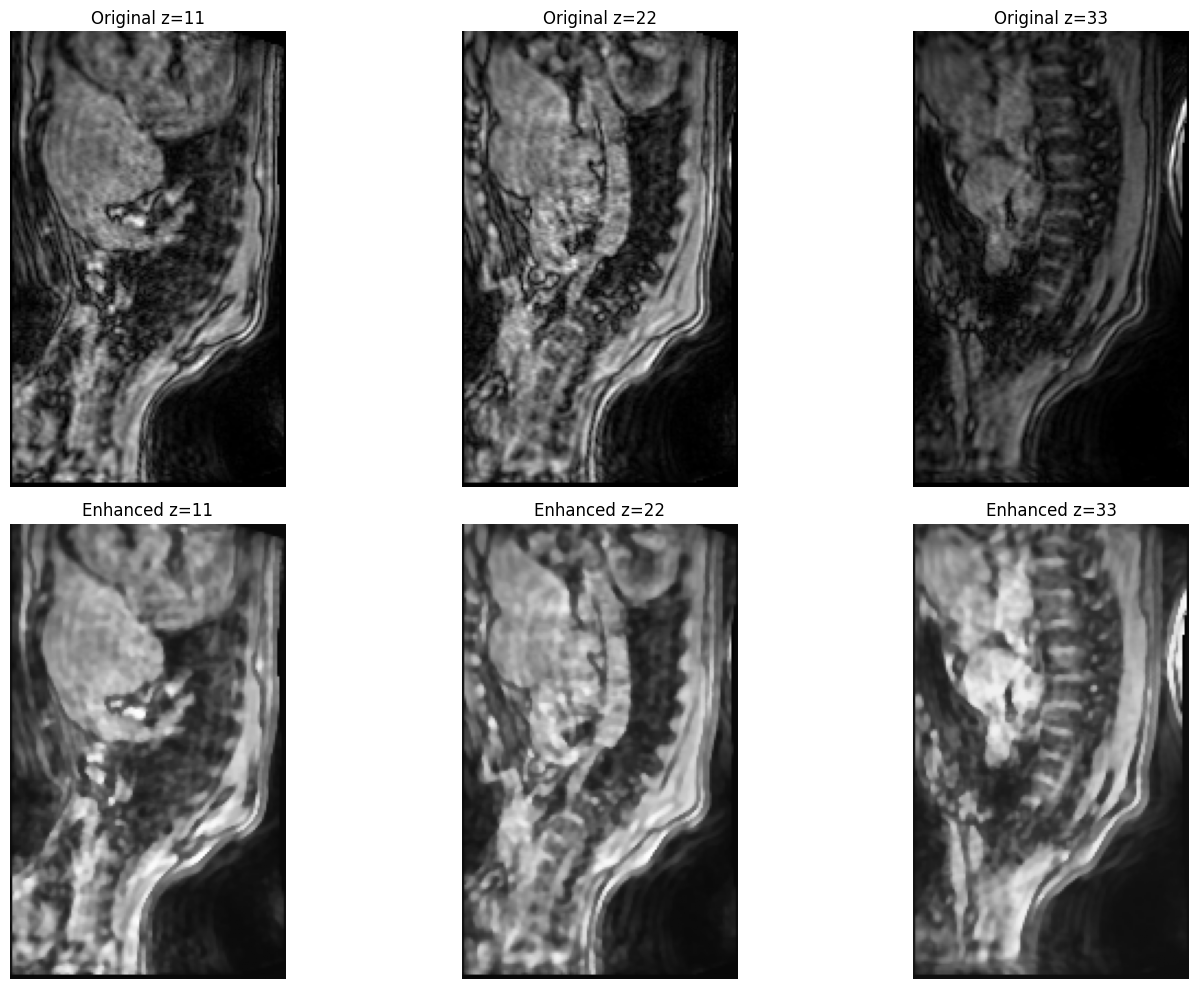

In [ ]:
orig = nib.load(str(sample_file)).get_fdata()
proc = nib.load(str(processed_dir / sample_file.name)).get_fdata()

z_slices = [
    orig.shape[2] // 4,
    orig.shape[2] // 2,
    3 * orig.shape[2] // 4
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, z in enumerate(z_slices):
    axes[0, i].imshow(orig[:, :, z].T,
                      cmap="gray",
                      origin="lower")
    axes[0, i].set_title(f"Original z={z}")
    axes[0, i].axis("off")

    axes[1, i].imshow(proc[:, :, z].T,
                      cmap="gray",
                      origin="lower")
    axes[1, i].set_title(f"Enhanced z={z}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


# compare RACELLETE data vs. 

Sample: VS010_f06_0000.nii.gz


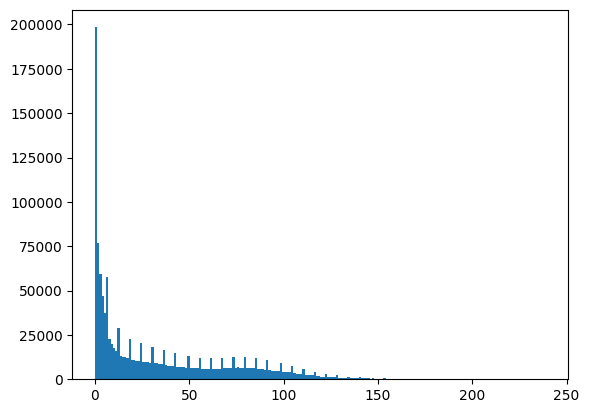

min/max: 0.0 239.0
mean/std: 34.144923415927025 36.8491689966036
spacing: (np.float32(1.9230769), np.float32(1.9230769), np.float32(2.0))
shape: (156, 208, 40)


In [33]:
original_dir = Path("/workspace/4dflows_magnitude_ahc/imageTs")

sample_file = random.choice(list(original_dir.glob("*.nii.gz")))

print("Sample:", sample_file.name)

img = nib.load(str(original_dir / sample_file.name))

data = img.get_fdata()

plt.hist(data.flatten(), bins=200)
plt.show()

print("min/max:", data.min(), data.max())
print("mean/std:", data.mean(), data.std())
print("spacing:", img.header.get_zooms())
print("shape:", data.shape)



Sample: VS026_f01_0000.nii.gz


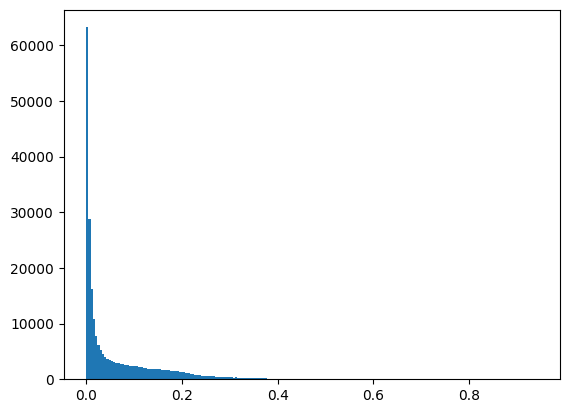

min/max: 9.769833013706375e-07 0.9422146081924438
mean/std: 0.06412253599439456 0.089545135780935
spacing: (np.float32(2.528376), np.float32(2.5759318), np.float32(2.7820063))
shape: (125, 84, 23)


In [32]:
racelet_dir = Path("/workspace/test_data/ao_imgs")
sample_file = random.choice(list(racelet_dir.glob("*.nii.gz")))
print("Sample:", sample_file.name)


img = nib.load(str(racelet_dir / sample_file.name))
data = img.get_fdata()


plt.hist(data.flatten(), bins=200)
plt.show()

print("min/max:", data.min(), data.max())
print("mean/std:", data.mean(), data.std())
print("spacing:", img.header.get_zooms())
print("shape:", data.shape)


# Comprehensive dataset characterization script(4dflow ahc)

In [34]:
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_gradient_magnitude

# Directory containing your real data
root = Path("/workspace/4dflows_magnitude_ahc/imageTs")

rows = []

files = sorted(root.glob("*.nii.gz"))

print(f"Found {len(files)} images")

for file in files:

    img = nib.load(str(file))
    data = img.get_fdata()

    spacing = img.header.get_zooms()[:3]
    shape = data.shape

    # intensity statistics
    minv = float(np.min(data))
    maxv = float(np.max(data))
    meanv = float(np.mean(data))
    stdv = float(np.std(data))

    p1 = float(np.percentile(data, 1))
    p5 = float(np.percentile(data, 5))
    p50 = float(np.percentile(data, 50))
    p95 = float(np.percentile(data, 95))
    p99 = float(np.percentile(data, 99))

    # physical FOV (mm)
    fov_x = shape[0] * spacing[0]
    fov_y = shape[1] * spacing[1]
    fov_z = shape[2] * spacing[2]

    # edge strength
    edge_strength = float(
        np.mean(
            gaussian_gradient_magnitude(data, sigma=1)
        )
    )

    rows.append({
        "file": file.name,

        "shape_x": shape[0],
        "shape_y": shape[1],
        "shape_z": shape[2],

        "spacing_x": spacing[0],
        "spacing_y": spacing[1],
        "spacing_z": spacing[2],

        "fov_x_mm": fov_x,
        "fov_y_mm": fov_y,
        "fov_z_mm": fov_z,

        "min": minv,
        "max": maxv,
        "mean": meanv,
        "std": stdv,

        "p1": p1,
        "p5": p5,
        "p50": p50,
        "p95": p95,
        "p99": p99,

        "edge_strength": edge_strength
    })

df = pd.DataFrame(rows)

df.to_csv("real_data_characteristics.csv", index=False)

print("\nSaved:")
print("real_data_characteristics.csv")

print("\nDataset summary:\n")
print(df.describe())


Found 563 images

Saved:
real_data_characteristics.csv

Dataset summary:

          shape_x  shape_y     shape_z   spacing_x   spacing_y   spacing_z  \
count  563.000000    563.0  563.000000  563.000000  563.000000  563.000000   
mean   134.206039    208.0   37.108348    1.927586    1.927586    1.989876   
std     11.721570      0.0   12.646043    0.022379    0.022379    0.054222   
min    126.000000    208.0   24.000000    1.923077    1.923077    1.700000   
25%    126.000000    208.0   26.000000    1.923077    1.923077    2.000000   
50%    126.000000    208.0   32.000000    1.923077    1.923077    2.000000   
75%    138.000000    208.0   44.000000    1.923077    1.923077    2.000000   
max    162.000000    208.0   72.000000    2.038461    2.038461    2.000000   

         fov_x_mm    fov_y_mm    fov_z_mm    min         max        mean  \
count  563.000000  563.000000  563.000000  563.0  563.000000  563.000000   
mean   258.764862  400.937836   73.487747    0.0  273.342806   42.65998

In [35]:
summary = {
    "n_images": len(df),

    "spacing_x_mean": df.spacing_x.mean(),
    "spacing_y_mean": df.spacing_y.mean(),
    "spacing_z_mean": df.spacing_z.mean(),

    "spacing_x_range":
        (df.spacing_x.min(), df.spacing_x.max()),

    "spacing_y_range":
        (df.spacing_y.min(), df.spacing_y.max()),

    "spacing_z_range":
        (df.spacing_z.min(), df.spacing_z.max()),

    "shape_x_range":
        (df.shape_x.min(), df.shape_x.max()),

    "shape_y_range":
        (df.shape_y.min(), df.shape_y.max()),

    "shape_z_range":
        (df.shape_z.min(), df.shape_z.max()),

    "mean_intensity":
        df["mean"].mean(),

    "std_intensity":
        df["std"].mean()
}

for k, v in summary.items():
    print(k, ":", v)

n_images : 563
spacing_x_mean : 1.9275856
spacing_y_mean : 1.9275856
spacing_z_mean : 1.9898758
spacing_x_range : (np.float32(1.9230769), np.float32(2.0384614))
spacing_y_range : (np.float32(1.9230769), np.float32(2.0384614))
spacing_z_range : (np.float32(1.7), np.float32(2.0))
shape_x_range : (np.int64(126), np.int64(162))
shape_y_range : (np.int64(208), np.int64(208))
shape_z_range : (np.int64(24), np.int64(72))
mean_intensity : 42.659988417382266
std_intensity : 35.96842214438648
